# CSCI6032 Homework 4

**Instructions**

* **Insert all code, plots, results, and discussion** into this Jupyter Notebook.
* Your homework should be submitted as a **single Jupyter Notebook** (.ipynb file) to **blackboard**.
* While working, you can Visual Studio Code, Jupyter Notebook or Google Colab.  If using Google Colab, export it as a Jupuyter Notebook (.ipynb)

You can answer mathematical questions either by:
* using LaTeX in a markdown cell, or
* handwriting your answer, then photographing or scanning it and using an AI/LLM to convert it into markdown and LaTeX, checking the conversion for accuracy before submitting.

## Problem 1: Sigmoid Function

The sigmoid function is often used in machine learning and statistics to model probabilities. It is defined as:

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

(a) Compute the value of $\sigma(0)$ and interpret its meaning in terms of probability. (4 points)

$\sigma(0) = \frac{1}{1+e^{0}} = \frac{1}{2}$. An input of 0 maps to probability 0.5: both outcomes are equally likely. This is the decision boundary, since positive inputs give probabilities above 0.5 and negative inputs give probabilities below 0.5.

(b) Show that $\sigma(-x) = 1 - \sigma(x)$. (6 points)

$$\sigma(-x) = \frac{1}{1 + e^{-(-x)}} = \frac{1}{1 + e^{x}}$$

$$1 - \sigma(x) = \frac{1 + e^{-x}}{1 + e^{-x}} - \frac{1}{1 + e^{-x}} = \frac{e^{-x}}{1 + e^{-x}}$$

Now multiply the top and bottom by $e^{x}$, using $e^{-x} \cdot e^{x} = 1$:

$$\frac{e^{-x} \cdot e^{x}}{(1 + e^{-x}) \cdot e^{x}} = \frac{1}{e^{x} + 1}$$

Both sides equal $\frac{1}{1 + e^{x}}$, so

$$\sigma(-x) = 1 - \sigma(x) \qquad \blacksquare$$

Flipping the sign of the input flips the probability. If σ(x) is the probability of class 1, then σ(−x) is the probability of class 0. For example, if σ(2) ≈ 0.88, then σ(−2) ≈ 0.12, and the two add up to 1.

at x = 0, σ(0) = 1 − σ(0) gives σ(0) = 1/2, which matches part (a).

(c) Plot the sigmoid function for $x \in [-10, 10]$ and describe its key properties (e.g., range, asymptotes, etc.). (6 points)

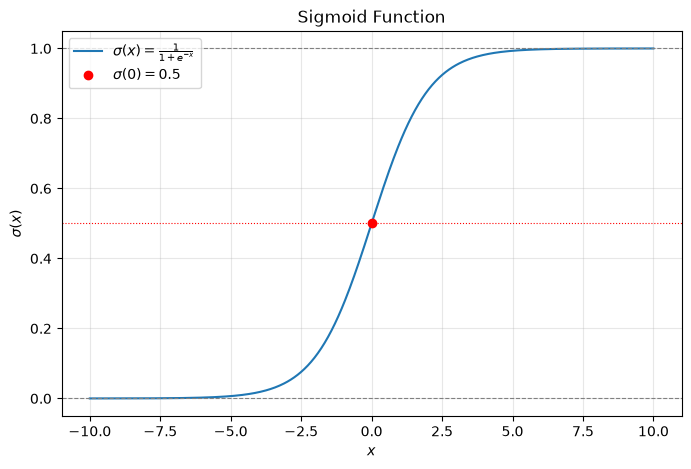

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 500)
sigma = 1 / (1 + np.exp(-x))

plt.figure(figsize=(8, 5))
plt.plot(x, sigma, label=r'$\sigma(x) = \frac{1}{1+e^{-x}}$')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)    # lower asymptote
plt.axhline(1, color='gray', linestyle='--', linewidth=0.8)    # upper asymptote
plt.axhline(0.5, color='red', linestyle=':', linewidth=0.8)
plt.plot(0, 0.5, 'ro', label=r'$\sigma(0) = 0.5$')
plt.xlabel('$x$')
plt.ylabel(r'$\sigma(x)$')
plt.title('Sigmoid Function')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Answer 1(c): key properties of $\sigma(x)$**

* **Domain:** all real numbers, $x \in (-\infty, \infty)$.
* **Range:** $(0, 1)$. The output is always strictly between 0 and 1 and never reaches either value, which is why it can be read as a probability.
* **Horizontal asymptotes:**
  * $y = 1$ as $x \to \infty$, because $e^{-x} \to 0$, so $\sigma(x) \to \frac{1}{1+0} = 1$.
  * $y = 0$ as $x \to -\infty$, because $e^{-x} \to \infty$, so $\sigma(x) \to 0$.
* **Midpoint:** $\sigma(0) = 0.5$. This is the inflection point, where the curve is steepest and changes from concave up to concave down.
* **Monotonic:** strictly increasing, so a larger $x$ always gives a larger $\sigma(x)$.
* **Symmetry:** $\sigma(-x) = 1 - \sigma(x)$ (part b), so the curve is point-symmetric about $(0, 0.5)$.
* **Saturation:** the slope is $\sigma'(x) = \sigma(x)\big(1 - \sigma(x)\big)$, which is at most $0.25$ (at $x = 0$) and nearly $0$ for $|x| \gtrsim 5$, where the curve is already very close to 0 or 1. In neural networks this flatness causes the *vanishing gradient* problem.
* **Smooth S-shape:** continuous and differentiable everywhere.

On the plot, the dashed gray lines at $y = 0$ and $y = 1$ are the asymptotes, and the red dot marks the midpoint $(0, 0.5)$.

## Problem 2: Hyperbolic Tangent Function

The hyperbolic tangent function, $\tanh(x)$, is another function commonly used in machine learning. It is defined as:

$$
\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}
$$

(a) Compute the value of $\tanh(0)$. (4 points)

(b) Show that $\tanh(-x) = -\tanh(x)$. (6 points)

(c) Plot the $\tanh(x)$ function for $x \in [-10, 10]$ and describe its key properties (e.g., range, asymptotes, symmetry, etc.). (6 points)

(d) Compare $\tanh(x)$ with the sigmoid function $\sigma(x)$ in terms of output range. (3 points)

**Answer 2(a)**

$$\tanh(0) = \frac{e^0 - e^{-0}}{e^0 + e^{-0}} = \frac{1 - 1}{1 + 1} = \frac{0}{2} = 0$$

**Answer 2(b)**

Substitute $-x$ for $x$ in the definition:

$$\tanh(-x) = \frac{e^{-x} - e^{-(-x)}}{e^{-x} + e^{-(-x)}} = \frac{e^{-x} - e^{x}}{e^{-x} + e^{x}}$$

The numerator is the negative of the original numerator, $e^{-x} - e^{x} = -(e^{x} - e^{-x})$, and the denominator is unchanged, since addition is commutative: $e^{-x} + e^{x} = e^{x} + e^{-x}$. Therefore

$$\tanh(-x) = \frac{-(e^{x} - e^{-x})}{e^{x} + e^{-x}} = -\frac{e^{x} - e^{-x}}{e^{x} + e^{-x}} = -\tanh(x) \qquad \blacksquare$$

So $\tanh$ is an **odd function**. As a check, at $x = 0$ the identity gives $\tanh(0) = -\tanh(0)$, so $\tanh(0) = 0$, matching part (a).

**Answer 2(c)**

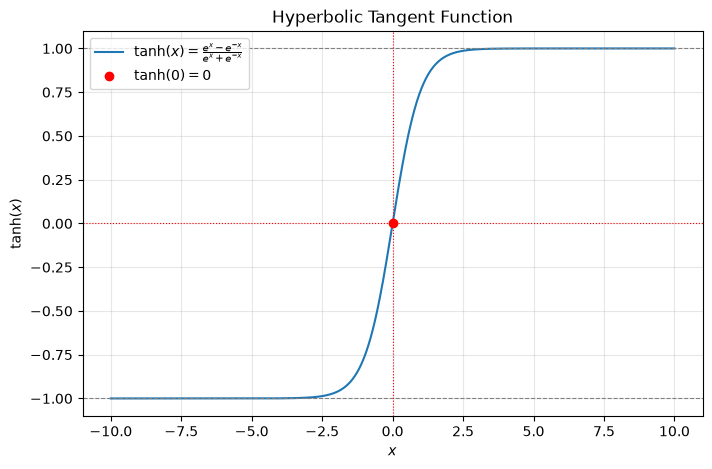

In [2]:
x = np.linspace(-10, 10, 500)
tanh = (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))

plt.figure(figsize=(8, 5))
plt.plot(x, tanh, label=r'$\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$')
plt.axhline(1, color='gray', linestyle='--', linewidth=0.8)     # upper asymptote
plt.axhline(-1, color='gray', linestyle='--', linewidth=0.8)    # lower asymptote
plt.axhline(0, color='red', linestyle=':', linewidth=0.8)
plt.axvline(0, color='red', linestyle=':', linewidth=0.8)
plt.plot(0, 0, 'ro', label=r'$\tanh(0) = 0$')
plt.xlabel('$x$')
plt.ylabel(r'$\tanh(x)$')
plt.title('Hyperbolic Tangent Function')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Key properties of $\tanh(x)$:**

* **Domain:** all real numbers, $x \in (-\infty, \infty)$.
* **Range:** $(-1, 1)$. The output is always strictly between $-1$ and $1$ and never reaches either value.
* **Horizontal asymptotes:** dividing the numerator and denominator by $e^{x}$ gives $\tanh(x) = \frac{1 - e^{-2x}}{1 + e^{-2x}}$.
  * $y = 1$ as $x \to \infty$, because $e^{-2x} \to 0$, so $\tanh(x) \to \frac{1 - 0}{1 + 0} = 1$.
  * $y = -1$ as $x \to -\infty$, because $\tanh$ is odd: $\tanh(x) = -\tanh(-x) \to -1$.
* **Symmetry:** odd function, $\tanh(-x) = -\tanh(x)$ (part b). The curve is point-symmetric about the origin.
* **Zero crossing / midpoint:** $\tanh(0) = 0$. This is the inflection point, where the curve is steepest and changes from concave up to concave down.
* **Monotonic:** strictly increasing.
* **Slope:** $\frac{d}{dx}\tanh(x) = 1 - \tanh^2(x)$, which is at most $1$ (at $x = 0$) and nearly $0$ for $|x| \gtrsim 3$. It saturates like the sigmoid, but faster.
* **Smooth S-shape:** continuous and differentiable everywhere.

On the plot, the dashed gray lines at $y = \pm 1$ are the asymptotes, and the red dot marks $(0, 0)$.

**Answer 2(d)**

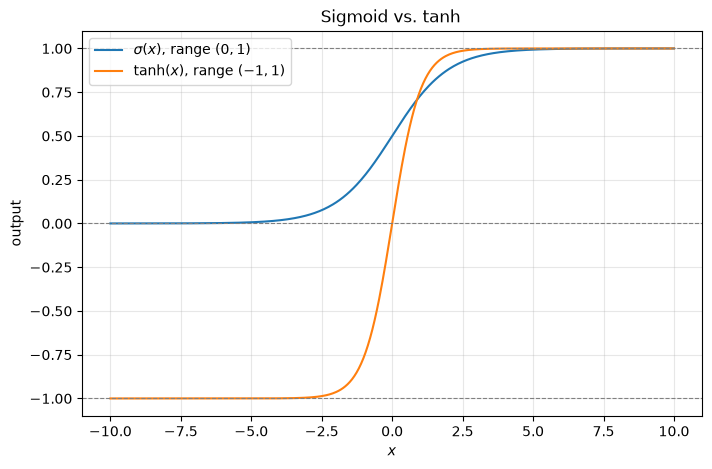

max |tanh(x) - (2*sigma(2x) - 1)| = 3.3306690738754696e-16


In [3]:
sigmoid = 1 / (1 + np.exp(-x))

plt.figure(figsize=(8, 5))
plt.plot(x, sigmoid, label=r'$\sigma(x)$, range $(0, 1)$')
plt.plot(x, tanh, label=r'$\tanh(x)$, range $(-1, 1)$')
for level in (-1, 0, 1):
    plt.axhline(level, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('$x$')
plt.ylabel('output')
plt.title(r'Sigmoid vs. $\tanh$')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Numerical check of the identity tanh(x) = 2*sigma(2x) - 1
print("max |tanh(x) - (2*sigma(2x) - 1)| =", np.max(np.abs(tanh - (2 / (1 + np.exp(-2 * x)) - 1))))

| | $\sigma(x)$ | $\tanh(x)$ |
|---|---|---|
| Output range | $(0, 1)$ | $(-1, 1)$ |
| Value at $x = 0$ | $0.5$ | $0$ |
| Width of range | $1$ | $2$ |
| Centered at | $0.5$ (always positive) | $0$ (zero-centered) |
| Maximum slope | $0.25$ | $1$ |

The two functions are closely related. $\tanh$ is a sigmoid that has been stretched vertically by 2, shifted down by 1 and compressed horizontally by 2:

$$2\sigma(2x) - 1 = \frac{2}{1 + e^{-2x}} - 1 = \frac{1 - e^{-2x}}{1 + e^{-2x}} = \frac{e^{x} - e^{-x}}{e^{x} + e^{-x}} = \tanh(x),$$

where the last step multiplies the top and bottom by $e^{x}$. The code above confirms this numerically (the difference is at floating-point round-off level).

Because its range is $(0, 1)$, $\sigma$ is the natural choice when the output must be a **probability**, such as the output layer of a binary classifier. $\tanh$ outputs can be negative, so they are **zero-centered**. This is often preferred in hidden layers, because zero-mean activations and the larger maximum slope give better-conditioned gradients during training.

## Problem 3: Linear Regression Implementation

You have already derived the normal equation for linear regression with a single feature (one-dimensional input). In this problem, you will implement linear regression from scratch using this equation.

**Requirements**

You are allowed to use NumPy for basic matrix operations, but you must not use any built-in functions or libraries for performing linear regression such as numpy.linalg.lstsq, numpy.polyfit, scipy.stats.linregress, or similar.

**Data**

Given a set of data points $(x_1, y_1), (x_2, y_2), \ldots, (x_n, y_n)$, write a function that fits a straight line $y = mx + c$ to the data by minimizing the mean squared error.

$$
\text{minimize } J(\Theta) = \sum_{i=1}^{m} \frac{1}{2} (h_{\Theta}(x^{(i)})-y^{(i)})^2
$$


The dataset for this problem can be found in the class github repository at

    https://github.com/dosirrah/CSCI6032_26F_MachineLearning/blob/main/hw4/p3_training_data.csv

This dataset contains two columns

* The first column conteains the input values $\mathbf{X}$.
* The second column contain the observed output values $y$.

To view the data, you can use the `head` command from the terminal as follows:

    % head p3_training_data.csv 
    X,y
    0.0,0.4967141530112327
    0.10101010101010101,0.11391758985007505
    0.20202020202020202,1.1499963521561645
    0.30303030303030304,2.271372616818459
    0.40404040404040403,0.7541400515935256
    0.5050505050505051,0.9860915764519412

The first column contains the inputs $\mathbf{X}$ and the second column the observed
data (outputs) $y$.  

The data is visualized below.

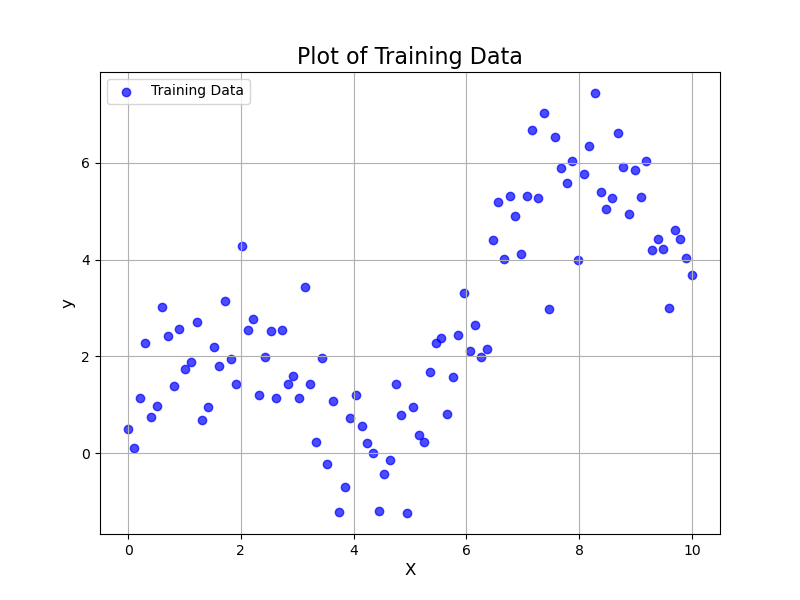


**Problem 3(a)** Implement linear regression for a single dimension using your solution to Problem 18 in HW3. (11 points)


**Answer 3(a)**

From HW3 Problem 18, setting $\nabla J(\Theta) = 0$ for $h_\Theta(x) = \Theta_0 + \Theta_1 x$ over $n$ training points gives the normal equation:

$$
\Theta_1 = \frac{n\sum_i x^{(i)}y^{(i)} - \sum_i x^{(i)}\sum_i y^{(i)}}{n\sum_i \left(x^{(i)}\right)^2 - \Big(\sum_i x^{(i)}\Big)^2},
\qquad
\Theta_0 = \frac{\sum_i y^{(i)} - \Theta_1 \sum_i x^{(i)}}{n}
$$

In the problem's notation $y = mx + c$, the slope is $m = \Theta_1$ and the intercept is $c = \Theta_0$.
The function `linear_regression` below computes these sums directly with NumPy. No regression library is used.
If all $x^{(i)}$ are identical (for example, a single point), the denominator is $0$ and the slope is undetermined. In that case the function returns a flat line through the mean of $y$. This case matters for $k = 1$ in Problem 4.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the data: local copy next to this notebook, falling back to the class repository.
try:
    data = pd.read_csv('p3_training_data.csv')
except FileNotFoundError:
    data = pd.read_csv('https://raw.githubusercontent.com/dosirrah/CSCI6032_26F_MachineLearning/main/hw4/p3_training_data.csv')

X = data['X'].to_numpy(dtype=float)
y = data['y'].to_numpy(dtype=float)
print(f"Loaded {len(X)} points, x in [{X.min()}, {X.max()}]")


def linear_regression(x, y):
    """Fit y = theta0 + theta1 * x using the normal equation (HW3 Problem 18).

    Returns (theta0, theta1), the intercept c and slope m that minimize
    J(theta) = sum_i 1/2 (theta0 + theta1 * x_i - y_i)^2.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)

    sum_x = np.sum(x)
    sum_y = np.sum(y)
    sum_xx = np.sum(x * x)
    sum_xy = np.sum(x * y)

    denom = n * sum_xx - sum_x**2
    if np.isclose(denom, 0.0):
        # All x are identical (e.g. one point): slope is undetermined, use a flat line through mean(y).
        return float(np.mean(y)), 0.0

    theta1 = (n * sum_xy - sum_x * sum_y) / denom
    theta0 = (sum_y - theta1 * sum_x) / n
    return float(theta0), float(theta1)


def predict(theta0, theta1, x):
    """Evaluate the fitted line h(x) = theta0 + theta1 * x."""
    return theta0 + theta1 * np.asarray(x, dtype=float)


# Sanity check on noise-free data: y = 2 + 3x must give theta0 = 2, theta1 = 3.
t0_check, t1_check = linear_regression([0, 1, 2, 3], [2, 5, 8, 11])
print(f"Sanity check (expect 2, 3): theta0 = {t0_check:.4f}, theta1 = {t1_check:.4f}")

Loaded 100 points, x in [0.0, 10.0]
Sanity check (expect 2, 3): theta0 = 2.0000, theta1 = 3.0000


**Problem 3(b): Create a Hold-out**

When training a machine learning model, it’s common practice to set aside a subset of the data called a hold-out set for testing. This ensures that the model is evaluated on data it hasn’t seen during training.

1.	Randomly select 10% of the dataset to form the *hold-out* set.
2.	Subtract the hold-out set from the training data, leaving 90% of the data for training.
3.	Use matplotlib to create a plot that:
 * Displays the training data.
 * Displays the hold-out data in a different color so that it can be visually distinguished from the training data.
 
Aside: to create the hold-out set, you can use `numpy.random.choice` or `numpy.random.shuffle`. (6 points)


Training points: 90, hold-out points: 10
Hold-out x values: [0.808 0.909 1.919 4.141 6.061 6.869 7.172 8.283 9.495 9.697]


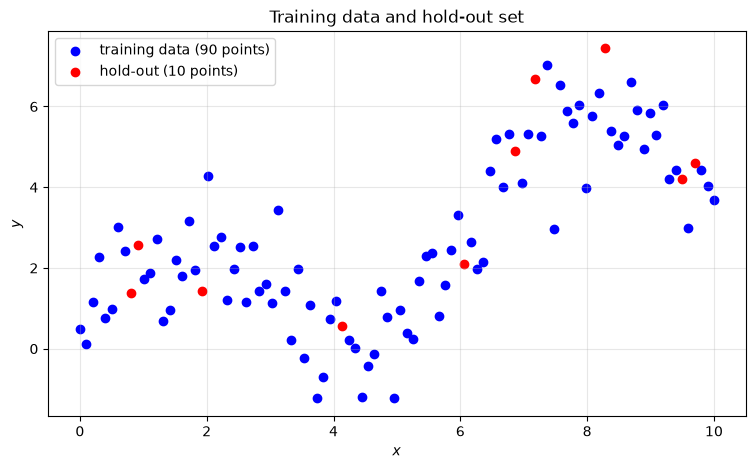

In [5]:
rng = np.random.default_rng(42)           # fixed seed so the split is reproducible
n = len(X)
n_holdout = int(round(0.10 * n))           # 10% of the data

# 1. Randomly select 10% of the indices (without replacement) for the hold-out set.
holdout_idx = np.sort(rng.choice(n, size=n_holdout, replace=False))
# 2. Subtract the hold-out from the full set; the remaining 90% is the training set.
train_idx = np.setdiff1d(np.arange(n), holdout_idx)

X_train, y_train = X[train_idx], y[train_idx]
X_hold, y_hold = X[holdout_idx], y[holdout_idx]

assert len(np.intersect1d(train_idx, holdout_idx)) == 0 and len(train_idx) + len(holdout_idx) == n
print(f"Training points: {len(X_train)}, hold-out points: {len(X_hold)}")
print("Hold-out x values:", np.round(X_hold, 3))

# 3. Plot the training data and the hold-out in different colors.
plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, color='blue', label=f'training data ({len(X_train)} points)')
plt.scatter(X_hold, y_hold, color='red', label=f'hold-out ({len(X_hold)} points)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('Training data and hold-out set')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Problem 3(c): Train the Model**

Using the training data excluding the hold-out, run your linear regression algorithm developed for 3(a).  This process is "training your model." (3 points)

**Answer 3(c)**


Trained model: y = 0.3214 + 0.4737 x   (intercept c = 0.3214, slope m = 0.4737)


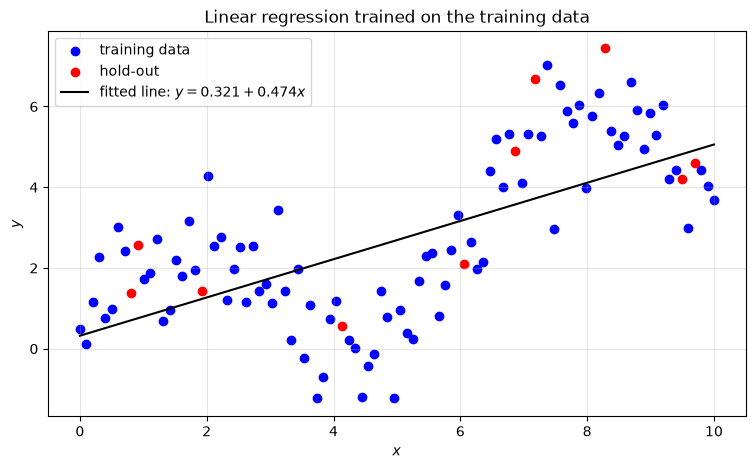

In [6]:
# Train: fit the line on the training data only (the hold-out is not used).
theta0, theta1 = linear_regression(X_train, y_train)
print(f"Trained model: y = {theta0:.4f} + {theta1:.4f} x   (intercept c = {theta0:.4f}, slope m = {theta1:.4f})")

x_line = np.linspace(0, 10, 500)
plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, color='blue', label='training data')
plt.scatter(X_hold, y_hold, color='red', label='hold-out')
plt.plot(x_line, predict(theta0, theta1, x_line), color='black',
         label=f'fitted line: $y = {theta0:.3f} + {theta1:.3f}x$')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('Linear regression trained on the training data')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The trained model is $\hat{y} = 0.3214 + 0.4737\,x$ (intercept $c = \Theta_0 = 0.3214$, slope $m = \Theta_1 = 0.4737$). It was fit on the 90 training points only.

**Problem 3(d): Test the Model**

Now we will test your model using the hold-out set. 

1. For each $x^{(i)}$ in your hold-out set, compute the predicted value $\hat{y}^{(i)}$.
2. Compute the *root-mean-square error (RMSE)* for the predicated values and the observed values in the hold-out set.

$$   
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} \left( \hat{y}^{(i)} - y^{(i)} \right)^2}
$$ 

(8 points)


In [7]:
def rmse(y_hat, y_obs):
    """Root-mean-square error between predictions and observations."""
    y_hat = np.asarray(y_hat, dtype=float)
    y_obs = np.asarray(y_obs, dtype=float)
    return np.sqrt(np.mean((y_hat - y_obs) ** 2))


# 1. Predict y_hat for every x in the hold-out set.
y_hat_hold = predict(theta0, theta1, X_hold)

print(pd.DataFrame({'x': X_hold,
                    'observed y': y_hold,
                    'predicted y_hat': y_hat_hold,
                    'y_hat - y': y_hat_hold - y_hold}).round(4).to_string(index=False))

# 2. RMSE on the hold-out set.
rmse_lr = rmse(y_hat_hold, y_hold)
print(f"\nHold-out RMSE (linear regression): {rmse_lr:.4f}")

     x  observed y  predicted y_hat  y_hat - y
0.8081      1.3805           0.7042    -0.6763
0.9091      2.5750           0.7521    -1.8229
1.9192      1.4271           1.2306    -0.1966
4.1414      0.5593           2.2833     1.7240
6.0606      2.1096           3.1924     1.0828
6.8687      4.9012           3.5752    -1.3260
7.1717      6.6762           3.7188    -2.9574
8.2828      7.4382           4.2451    -3.1931
9.4949      4.2151           4.8193     0.6042
9.6970      4.6069           4.9150     0.3081

Hold-out RMSE (linear regression): 1.7066


**Answer 3(d):** the hold-out RMSE of the linear regression model is **1.7066**.

The errors are not random noise around the line; they are systematic. The data follows a wave on top of an upward trend, and a single straight line cannot bend to follow it. The model under-predicts near the peak around $x \approx 7$–$8.3$ (errors of about $-3$) and over-predicts in the trough around $x \approx 4$ (error $+1.7$). This underfitting (high bias) is what LWLR addresses in Problem 4.

*(The exact numbers depend on the random hold-out; the split uses seed 42 so the results are reproducible.)*

## Problem 4: Locally Weighted Linear Regression

With Locally-Weighted Linear Regression (LWLR), we have no separate training phase.  Instead LWLR keeps all or a subset of the training data as part of a hypothesis $h$ (a.k.a., the model).   When an input vector  $\mathbf{x}$  is passed to the model, it infers the output $y$ by performing a linear regression, placing more weight on the training points $\mathbf{x}^{(i)}$  that are closer to  $\mathbf{x}$. The way proximity is measured and how nearby points are weighted is determined by a *kernel function.*


<>:12: SyntaxWarning: invalid escape sequence '\{'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\{'
<>:25: SyntaxWarning: invalid escape sequence '\m'
C:\Users\bator\AppData\Local\Temp\ipykernel_4392\4229381177.py:12: SyntaxWarning: invalid escape sequence '\{'
  ax.text(0.5, 0.85, '$\{(\mathbf{x}^{(i)}, y^{(i)})\}$', ha='center', va='center', fontsize=16)
C:\Users\bator\AppData\Local\Temp\ipykernel_4392\4229381177.py:25: SyntaxWarning: invalid escape sequence '\m'
  ax.text(0.2, 0.4, 'input $\mathbf{x}$', ha='right', va='center', fontsize=16)


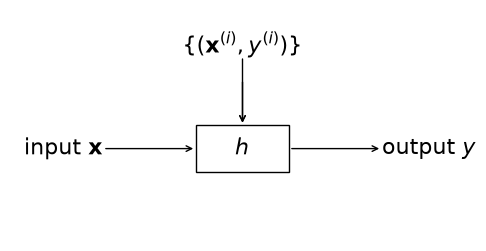

In [8]:
## Draw plot
# If one wants to avoid including images and is willing to create simple
# diagrams programmatically, one can use matplotlib to create diagrams.
import matplotlib.pyplot as plt

# Create a figure and axis
fig, ax = plt.subplots(figsize=(6,3))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.text(0.5, 0.85, '$\{(\mathbf{x}^{(i)}, y^{(i)})\}$', ha='center', va='center', fontsize=16)

# Draw arrows into and out of the training algo box.
ax.annotate("", xy=(0.5, 0.8), xytext=(0.5, 0.5),
            arrowprops=dict(arrowstyle="<-"))

# Draw arrow from the training algo box to the hypothesis (model) box.
ax.annotate("", xy=(0.5, 0.7), xytext=(0.5, 0.5),
            arrowprops=dict(arrowstyle="<-"))

ax.add_patch(plt.Rectangle((0.4, 0.3), 0.2, 0.2, edgecolor='black', facecolor='none'))
ax.text(0.5, 0.4, '$h$', ha='center', va='center', fontsize=16)

ax.text(0.2, 0.4, 'input $\mathbf{x}$', ha='right', va='center', fontsize=16)
ax.text(0.8, 0.4, 'output $y$', ha='left', va='center', fontsize=16)

# Draw arrows into and out of the hypothesis (a.k.a., the model).
ax.annotate("", xy=(0.2, 0.4), xytext=(0.4, 0.4),
            arrowprops=dict(arrowstyle="<-"))
ax.annotate("", xy=(0.6, 0.4), xytext=(0.8, 0.4),
            arrowprops=dict(arrowstyle="<-"))

ax.axis('off')

plt.show()

One common and simple kernel function is **$k$-nearest neighbors (k-NN) regression**.  In $k-NN$ regression, the kernel function assigns equal weights to the $k$-nearest neighbors to input $\mathbf{x}$ and assigs zero weight to all other data points in the training set.

The $k-NN$ kernel is computationally scalable because the normal equation deriving the 
coefficients of the linear model is evaluated only on the $k$-nearest neighbors.



**Problem 4(a)** Implement Locally-Weighted Linear Regression using a k-NN kernel.  Your code should use the normal equation you derived in Problem 18 in HW3 and also used in the linear regression implementation in Problem 3.  Analogous to Problem 3, do not use any existing implementation of LWLR.  You may use NumPy for basic matrix operations.  (13 points)

**Answer 4(a)**

The model stores the training data; there is no separate training phase. To predict $y$ for a query $x$:

1. Compute the distance $|x^{(i)} - x|$ from the query to every training input.
2. **k-NN kernel:** give weight $1$ to the $k$ nearest training points and weight $0$ to all others.
3. Fit a line $\Theta_0 + \Theta_1 x$ to just those $k$ points with the normal equation, reusing `linear_regression` from 3(a).
4. Return that local line evaluated at the query point, $\hat{y} = \Theta_0 + \Theta_1 x$.

Every query gets its own local line. With $k = 1$ the single neighbor makes the denominator of the normal equation $0$, so the fit returns that point's $y$ ("use the value of the closest point"). With $k$ equal to the size of the training set, every query uses all the data, and LWLR reduces to ordinary linear regression.

In [9]:
class LWLR:
    """Locally-weighted linear regression with a k-nearest-neighbors kernel."""

    def __init__(self, X_train, y_train, k):
        self.X_train = np.asarray(X_train, dtype=float)
        self.y_train = np.asarray(y_train, dtype=float)
        if not 1 <= k <= len(self.X_train):
            raise ValueError(f"k must be between 1 and {len(self.X_train)}")
        self.k = k

    def predict(self, x_query):
        """Predict y for each query x by fitting a line to its k nearest training points."""
        queries = np.atleast_1d(np.asarray(x_query, dtype=float))
        y_pred = np.empty(len(queries))
        for j, xq in enumerate(queries):
            distances = np.abs(self.X_train - xq)
            nearest = np.argsort(distances, kind='stable')[:self.k]     # weight 1 for these, 0 for the rest
            theta0_local, theta1_local = linear_regression(self.X_train[nearest], self.y_train[nearest])
            y_pred[j] = predict(theta0_local, theta1_local, xq)
        return y_pred


# Sanity checks on noise-free linear data y = 1 + 2x:
x_lin = np.arange(10.0)
y_lin = 1 + 2 * x_lin
print("k=3 on a perfect line (expect 1 + 2*4.3 = 9.6):", LWLR(x_lin, y_lin, k=3).predict(4.3))
print("k=1 returns the closest point's y (expect 9.0):", LWLR(x_lin, y_lin, k=1).predict(4.3))

k=3 on a perfect line (expect 1 + 2*4.3 = 9.6): [9.6]
k=1 returns the closest point's y (expect 9.0): [9.]


**Problem 4(b)** Use the same training data and hold-out as in Problem 3.  Initialize the LWLR model with the training data excluding the hold-out.
Create a $xy$ plot with the observed values and predictions in the $y$ and the input along the $x$ axis.  On this plot, show the training data in blue, the hold out in red, and a green curve generated by sweeping the input $x$ from 0 to 10 in 500 increments.  Use $k=10$. (8 points)

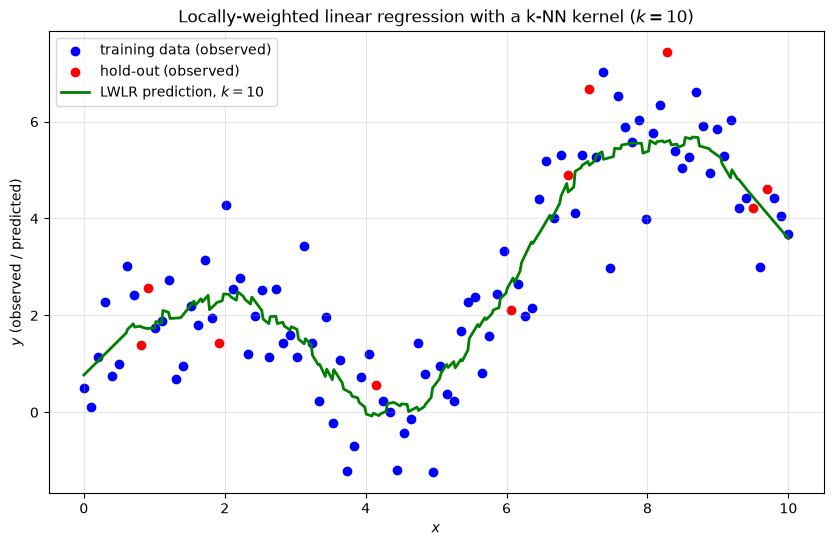

In [10]:
lwlr_10 = LWLR(X_train, y_train, k=10)     # model initialized with the training data (hold-out excluded)

x_sweep = np.linspace(0, 10, 500)          # sweep x from 0 to 10 in 500 increments
y_sweep = lwlr_10.predict(x_sweep)

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', label='training data (observed)')
plt.scatter(X_hold, y_hold, color='red', label='hold-out (observed)')
plt.plot(x_sweep, y_sweep, color='green', linewidth=2, label='LWLR prediction, $k = 10$')
plt.xlabel('$x$')
plt.ylabel('$y$ (observed / predicted)')
plt.title('Locally-weighted linear regression with a k-NN kernel ($k = 10$)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Problem 4(c): Test the Model**

Write code to compute the *RMSE* for the hold-out with $k=3$, $k=10$ and $k=90$. Present the resulting RMSE values in a table with one row for each $k$ value and a row containig the results form 3(d). Did LWLR outperform linear regression?  Why?  (8 points)

In [11]:
rows = []
for k in [3, 10, 90]:
    model_k = LWLR(X_train, y_train, k=k)
    rows.append({'model': f'LWLR, k = {k}', 'hold-out RMSE': rmse(model_k.predict(X_hold), y_hold)})
rows.append({'model': 'Linear regression (3(d))', 'hold-out RMSE': rmse_lr})

rmse_table = pd.DataFrame(rows).round(4)
rmse_table

,model,hold-out RMSE
0,"LWLR, k = 3",1.1388
1,"LWLR, k = 10",0.9054
2,"LWLR, k = 90",1.7066
3,Linear regression (3(d)),1.7066


**Answer 4(c)**

| Model | Hold-out RMSE |
|---|---|
| LWLR, $k = 3$ | 1.1388 |
| LWLR, $k = 10$ | **0.9054** |
| LWLR, $k = 90$ | 1.7066 |
| Linear regression (3(d)) | 1.7066 |

**Did LWLR outperform linear regression?** Yes, for $k = 3$ and $k = 10$. With $k = 10$, LWLR cuts the hold-out RMSE from 1.71 to 0.91, about 47% lower. For $k = 90$ it ties exactly.

**Why:**

* **The data is nonlinear.** It is a wave on top of an upward trend. Global linear regression fits one straight line to everything, so it underfits (high bias) and makes large systematic errors at the peaks and troughs. LWLR fits a separate line to the neighborhood of each query point. Over a short range the curve is approximately linear, so the local lines follow the bends.
* **$k = 90$ is identical to linear regression.** The training set has exactly 90 points, so every query's "90 nearest neighbors" is the entire training set. Every query fits the same global line, which gives the same RMSE as 3(d).
* **$k = 3$ is worse than $k = 10$.** A line through only 3 noisy points is very sensitive to the noise in those points (high variance). With $k = 10$, the local fit averages out more noise while still being local enough to follow the curve.

This is the **bias–variance tradeoff**. Small $k$ gives low bias but high variance, and large $k$ gives low variance but high bias. $k = 10$ is the best of the three values tested.
With only 10 hold-out points, the RMSE values are themselves noisy estimates. In practice, $k$ would be chosen by cross-validation.

**Probem 4(d): Plot Regression Curves**

Generate the same plot as in 4(b), except add separate curves for $k=1$, $k=3$, $k=10$,
and $k=90$ while varying $x$ from 0 to 10 in 500 increments. $k=1$ means "use the value
of the closest point." (8 points)

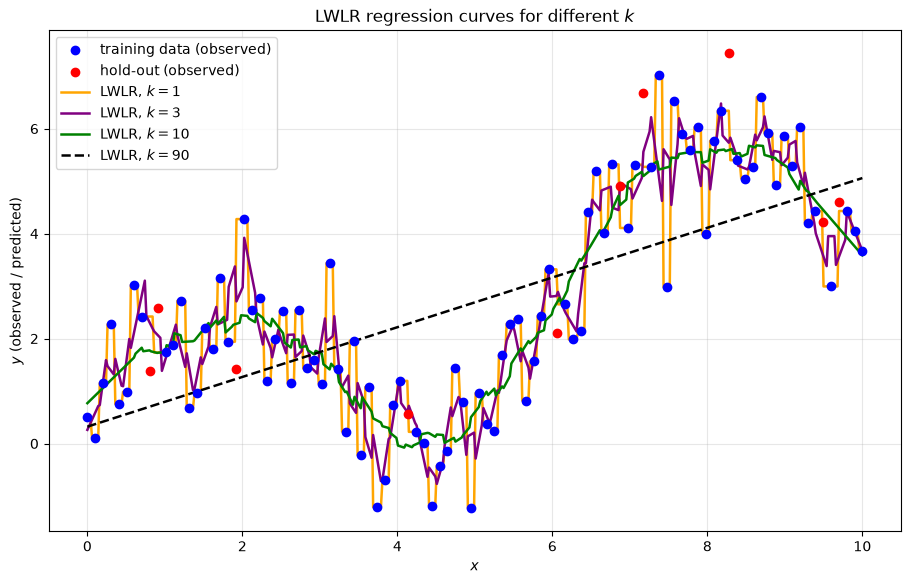

In [12]:
plt.figure(figsize=(11, 6.5))
plt.scatter(X_train, y_train, color='blue', label='training data (observed)', zorder=3)
plt.scatter(X_hold, y_hold, color='red', label='hold-out (observed)', zorder=3)

curve_styles = {1: ('orange', '-'), 3: ('purple', '-'), 10: ('green', '-'), 90: ('black', '--')}
for k, (color, style) in curve_styles.items():
    model_k = LWLR(X_train, y_train, k=k)
    plt.plot(x_sweep, model_k.predict(x_sweep), color=color, linestyle=style, linewidth=1.8,
             label=f'LWLR, $k = {k}$')

plt.xlabel('$x$')
plt.ylabel('$y$ (observed / predicted)')
plt.title('LWLR regression curves for different $k$')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Observations (4(d)):**

* **$k = 1$ (orange):** a step function that jumps to the $y$ of whichever training point is closest. It passes through every training point (zero training error) but reproduces all of the noise. This is the most extreme overfitting (highest variance).
* **$k = 3$ (purple):** still very jagged. Each local line is fit to only 3 noisy points, so the curve swings sharply between neighbors.
* **$k = 10$ (green):** a fairly smooth curve that follows the underlying wave: up to $x \approx 2$, down into the trough near $x \approx 4.5$, up to the peak near $x \approx 8$, then down again. This is the best balance, consistent with it having the lowest RMSE in 4(c).
* **$k = 90$ (black dashed):** every query uses all 90 training points, so the curve is the straight line from Problem 3. It is smooth but misses the shape of the data (underfitting, high bias).

As $k$ increases, the curve gets smoother and moves from following the noise ($k = 1$) to ignoring the structure ($k = 90$). $k$ acts as the model's smoothing (complexity) hyperparameter.